## import thư viện và đọc dữ liệu

In [16]:
from pathlib import Path

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score
)
import matplotlib.pyplot as plt
import joblib

RANDOM_STATE = 42
TARGET = "Attack_type"

def find_data_file(filename: str) -> Path:
    # Find the files independently of the notebook working directory.
    cwd = Path.cwd()
    candidates = [
        cwd / filename,
        cwd / "splitted data" / filename,
        cwd / ".." / "splitted data" / filename,
        cwd / ".." / ".." / "splitted data" / filename,
        cwd / "data" / filename,
    ]

    for parent in (cwd, *cwd.parents):
        candidates.append(parent / "splitted data" / filename)

    for path in candidates:
        path = path.resolve()
        if path.is_file():
            return path

    searched = "\n".join(f"  - {path.resolve()}" for path in candidates)
    raise FileNotFoundError(
        f"Không tìm thấy {filename}. Các đường dẫn đã kiểm tra:\n{searched}"
    )

train_path = find_data_file("train.csv")
validation_path = find_data_file("validation.csv")

train_df = pd.read_csv(train_path)
validation_df = pd.read_csv(validation_path)

print("Train shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Target:", TARGET)
print("Train file:", train_path)
print("Validation file:", validation_path)

Train shape: (82, 1)
Validation shape: (17686, 83)
Target: Attack_type
Train file: C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\splitted data\train.csv.gz
Validation file: C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\splitted data\validation.csv.gz


## tách x/y và khai báo pipeline

In [18]:
# Fix: train_df may have been overwritten by the feature-name list.
if TARGET not in train_df.columns:
    train_df = pd.read_csv(train_path)

# If the CSV still does not contain the target, rebuild using the known feature names.
if TARGET not in train_df.columns:
    train_df = pd.read_csv(train_path, names=feature_columns + [TARGET])

X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]

X_validation = validation_df.drop(columns=[TARGET])
y_validation = validation_df[TARGET]

categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = [col for col in X_train.columns if col not in categorical_features]

print("Categorical features:", categorical_features)
print("Number of numeric features:", len(numeric_features))

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", "passthrough", numeric_features),
    ],
    remainder="drop"
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", rf_model)
])

model_pipeline

Categorical features: ['id.orig_p']
Number of numeric features: 81


C:\Users\hauth\AppData\Local\Temp\ipykernel_18600\1514227660.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defau

## 3-Fold Cross-Validation trên tập train

In [ ]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted",
    "macro_precision": "precision_macro",
    "macro_recall": "recall_macro"
}

cv_results = cross_validate(
    estimator=model_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=1
)

cv_results_df = pd.DataFrame({
    "Fold": [1, 2, 3],
    "accuracy": cv_results["test_accuracy"],
    "macro_f1": cv_results["test_macro_f1"],
    "weighted_f1": cv_results["test_weighted_f1"],
    "macro_precision": cv_results["test_macro_precision"],
    "macro_recall": cv_results["test_macro_recall"]
})

display(cv_results_df)

summary = cv_results_df.drop(columns="Fold").agg(["mean", "std"]).T
summary.columns = ["Mean", "Std"]
print("3-Fold CV summary:")
display(summary)

,Fold,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
0,1,0.997965,0.967206,0.997957,0.988597,0.951917
1,2,0.997746,0.960544,0.997733,0.984267,0.944463
2,3,0.997855,0.967818,0.997857,0.958669,0.981622


3-Fold CV summary:


,Mean,Std
accuracy,0.997855,0.000109
macro_f1,0.965189,0.004034
weighted_f1,0.997849,0.000112
macro_precision,0.977178,0.016175
macro_recall,0.959334,0.019658


## Huấn luyện trên toàn bộ tập train và đánh giá validation

In [ ]:
model_pipeline.fit(X_train, y_train)

y_pred = model_pipeline.predict(X_validation)

validation_metrics = {
    "accuracy": accuracy_score(y_validation, y_pred),
    "macro_f1": f1_score(y_validation, y_pred, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_validation, y_pred, average="weighted", zero_division=0),
    "macro_precision": precision_score(y_validation, y_pred, average="macro", zero_division=0),
    "macro_recall": recall_score(y_validation, y_pred, average="macro", zero_division=0),
}
print("Validation metrics:")
for metric_name, metric_value in validation_metrics.items():
    print(f"{metric_name}: {metric_value:.6f}")
print("\\nClassification report:")
print(classification_report(y_validation, y_pred, zero_division=0))

Validation metrics:
accuracy: 0.998360
macro_f1: 0.980974
weighted_f1: 0.998354
macro_precision: 0.997335
macro_recall: 0.967969
\nClassification report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.98      1.00      0.99      1143
            DDOS_Slowloris       1.00      0.99      0.99        80
             DOS_SYN_Hping       1.00      1.00      1.00     13513
              MQTT_Publish       1.00      1.00      1.00       621
Metasploit_Brute_Force_SSH       1.00      1.00      1.00         5
             NMAP_FIN_SCAN       1.00      0.75      0.86         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       300
             NMAP_TCP_scan       1.00      1.00      1.00       151
             NMAP_UDP_SCAN       0.99      0.99      0.99       387
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       302
               Thing_Speak       1.00      0.99      0.99      1147
                Wipro_bulb   

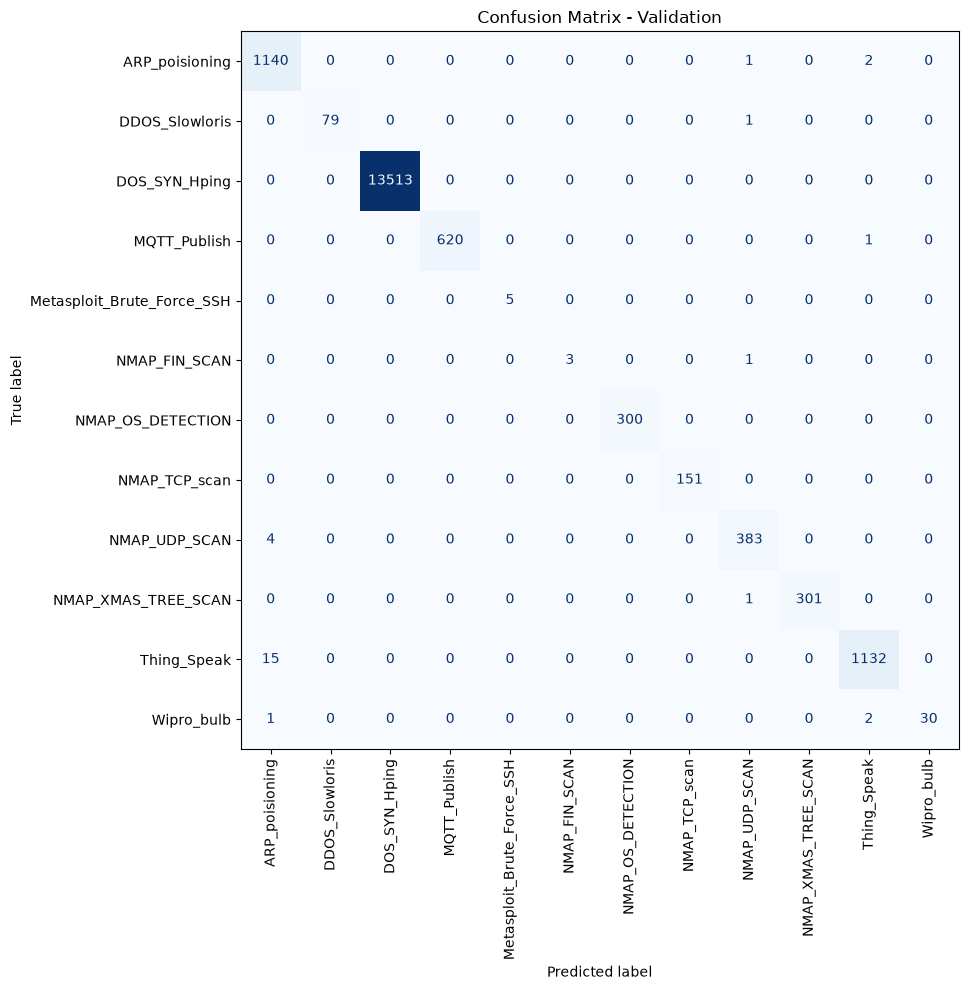

In [ ]:
# Confusion matrix trên validation
labels = model_pipeline.named_steps["model"].classes_
cm = confusion_matrix(y_validation, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - Validation")
plt.tight_layout()
plt.show()